In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

train = pd.read_parquet("../data/processed/train_woe.parquet")
test  = pd.read_parquet("../data/processed/test_woe.parquet")
X_train, y_train = train.drop(columns="target"), train["target"]
X_test,  y_test  = test.drop(columns="target"),  test["target"]

# Same model as notebook 04
model = LogisticRegression(C=10, max_iter=1000).fit(X_train, y_train)
p_train = model.predict_proba(X_train)[:, 1]
p_test  = model.predict_proba(X_test)[:, 1]

In [2]:
# Scaling: 600 points at 50:1 good/bad odds, every +20 points doubles the odds
BASE_SCORE, BASE_ODDS, PDO = 600, 50, 20
factor = PDO / np.log(2)
offset = BASE_SCORE - factor * np.log(BASE_ODDS)

def pd_to_score(p):
    # score = offset - factor * ln(bad odds); higher score = lower risk
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return offset - factor * np.log(p / (1 - p))

score_train = pd.Series(pd_to_score(p_train))
score_test  = pd.Series(pd_to_score(p_test))
print(score_train.describe().round(1))

count    306462.0
mean        544.8
std          16.8
min         488.1
25%         533.0
50%         543.6
75%         555.3
max         610.3
dtype: float64


In [3]:
bands = pd.qcut(score_test, 10, duplicates="drop")
band_tbl = (pd.DataFrame({"band": bands, "bad": y_test.values})
            .groupby("band", observed=True)["bad"].agg(["mean", "size"]).round(3))
band_tbl.columns = ["bad_rate", "n"]
display(band_tbl)   # bad rate should fall as the score band increases

,bad_rate,n
band,,
"(486.75300000000004, 524.04]",0.277,28303
"(524.04, 530.593]",0.227,28303
"(530.593, 535.534]",0.195,28302
"(535.534, 539.898]",0.171,28303
"(539.898, 544.06]",0.154,28302
"(544.06, 548.399]",0.132,28303
"(548.399, 553.159]",0.118,28302
"(553.159, 558.985]",0.098,28303
"(558.985, 568.062]",0.076,28303


In [4]:
def psi_continuous(expected, actual, n_bins=10):
    # Bin edges come from the training (expected) distribution
    edges = np.quantile(expected, np.linspace(0, 1, n_bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    e = pd.cut(expected, edges).value_counts(normalize=True, sort=False).clip(lower=1e-6)
    a = pd.cut(actual,   edges).value_counts(normalize=True, sort=False).clip(lower=1e-6)
    return ((a - e) * np.log(a / e)).sum()

print("Score PSI (train vs test):", round(psi_continuous(score_train, score_test), 4))
# Rule of thumb: < 0.10 stable, 0.10-0.25 moderate shift, > 0.25 significant shift

Score PSI (train vs test): 0.001


In [5]:
def psi_discrete(expected, actual):
    # WoE features take few distinct values, so compare value frequencies directly
    e, a = expected.round(6), actual.round(6)
    cats = sorted(set(e.unique()) | set(a.unique()))
    pe = e.value_counts(normalize=True).reindex(cats).fillna(0).clip(lower=1e-6)
    pa = a.value_counts(normalize=True).reindex(cats).fillna(0).clip(lower=1e-6)
    return ((pa - pe) * np.log(pa / pe)).sum()

feature_psi = pd.Series({c: psi_discrete(X_train[c], X_test[c]) for c in X_train.columns})
feature_psi.sort_values(ascending=False).round(4)

mort_acc              0.2019
dti                   0.0415
inq_last_6mths        0.0407
revol_util            0.0275
credit_history_yrs    0.0183
fico_avg              0.0050
annual_inc            0.0044
home_ownership        0.0039
loan_to_income        0.0035
purpose               0.0023
dtype: float64

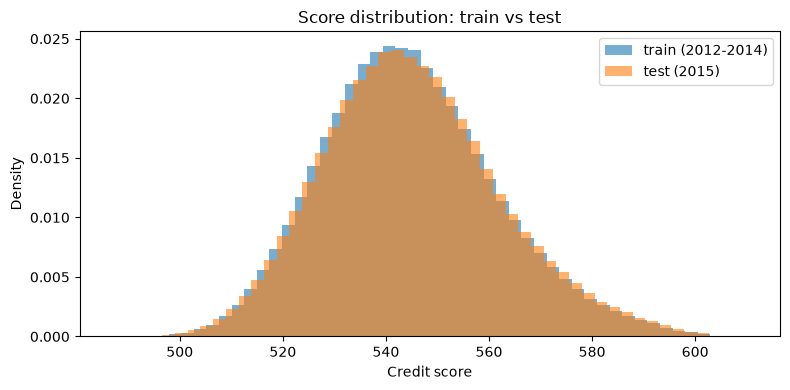

In [6]:
import os
os.makedirs("../reports/figures", exist_ok=True)

plt.figure(figsize=(8, 4))
plt.hist(score_train, bins=50, alpha=0.6, density=True, label="train (2012-2014)")
plt.hist(score_test,  bins=50, alpha=0.6, density=True, label="test (2015)")
plt.xlabel("Credit score"); plt.ylabel("Density"); plt.legend()
plt.title("Score distribution: train vs test")
plt.tight_layout()
plt.savefig("../reports/figures/score_distribution.png", dpi=150)
plt.show()

In [7]:
# Check whether mort_acc is reported consistently across issue years
chk = pd.read_parquet("../data/processed/accepted_clean.parquet",
                      columns=["issue_d", "mort_acc"])
chk["year"] = chk["issue_d"].dt.year

chk[chk["year"].between(2012, 2015)].groupby("year")["mort_acc"].agg(
    missing_share=lambda s: s.isna().mean(),
    mean_value="mean",
).round(3)

,missing_share,mean_value
year,,
2012,0.139,1.477
2013,0.000,1.725
2014,0.000,1.701
2015,0.000,1.558
